# Machine Learning-Based Statistical Arbitrage & Pair Trading Strategy Using Supervised Learning Across Equity and ETF Pairs

**Course:** Machine Learning in Quantitative Finance (MSQF Semester III)  
**Department:** Department of Statistics, Ramanujan School of Mathematical Sciences, Pondicherry University  
**Topic:** Statistical Arbitrage, Cointegration, Meta-Labeling, and Multi-Model Supervised Classification on Real Financial Assets  

---

## Executive Summary & Research Motivation

Traditional statistical arbitrage and pairs trading strategies rely on the assumption of **spread mean-reversion**: when the spread between two cointegrated assets deviates beyond a statistical threshold (e.g., standardized $Z$-score $|Z| \ge 2.0$), a contrarian trade is initiated under the expectation that the spread will revert to its long-run equilibrium ($Z \approx 0$).

However, in institutional financial markets, naive pairs trading faces two major failure modes:
1. **Structural Breaks & Macro Regime Shifts:** Cointegration relationships can break down due to shifting corporate fundamentals, regulatory actions, or macroeconomic cycles. A naive rule continues holding or averaging into an explosive divergence, suffering severe drawdowns.
2. **Transaction Cost Whipsaws & False Breakouts:** Frequent small deviations in volatile or weakly cointegrated assets trigger trades that fail to overcome transaction costs and bid-ask slippage.

### Core Research Question
> **Can supervised machine learning models act as an intelligent risk and quality filter (meta-labeling) to accurately predict whether a candidate pair-trading signal will be profitable under realistic transaction frictions, and which of the 6 core MSQF supervised models achieves the superior risk-adjusted performance across real equity and ETF pairs?**

To rigorously answer this question without data snooping or lookahead bias, this project:
- Evaluates **historical daily market price data (2015–2024)** across 10 liquid US equities and ETFs spanning 5 distinct sector and macro pairs:
  - **Market Benchmark:** `SPY` (SPDR S&P 500 ETF Trust)
  - **Consumer Staples:** `KO` (Coca-Cola) vs. `PEP` (PepsiCo)
  - **Energy (Oil & Gas):** `XOM` (ExxonMobil) vs. `CVX` (Chevron)
  - **Banking & Financials:** `JPM` (JPMorgan Chase) vs. `BAC` (Bank of America)
  - **Integrated Energy Majors:** `BP` (BP p.l.c.) vs. `SHEL` (Shell plc)
  - **Macro Asset Pair:** `GLD` (SPDR Gold Shares) vs. `SPY` (S&P 500 ETF)
- Engineers a comprehensive **12-dimensional quantitative feature space** capturing mean-reversion half-life, fractal memory (Hurst exponent), unit-root stationarity (ADF $p$-value), serial autocorrelations, and volatility ratios.
- Formulates a **Triple-Barrier Meta-Labeling** target with proportional transaction costs (10 bps round-trip).
- Evaluates and dissects the **6 core supervised models from the MSQF syllabus**:
  1. **Logistic Regression** ($L_2$ regularized linear log-odds classifier)
  2. **Gaussian Naive Bayes** (probabilistic generative model with class-conditional priors)
  3. **K-Nearest Neighbors (KNN)** (non-parametric metric space instance learner)
  4. **Decision Tree (CART)** (hierarchical binary decision rule learner)
  5. **Random Forest** (bagging ensemble of 150 decorrelated decision trees)
  6. **Support Vector Machine (SVM RBF)** (maximum-margin kernel classifier)
- Uses **Walk-Forward Cross-Validation with an Embargo/Purge Period** equal to the holding horizon to eliminate serial data leakage.
- Conducts an event-driven backtest contrasting **Traditional Strategy (No ML)** against **ML-Filtered Strategies**.


## Mathematical & Theoretical Foundations

### 1. Asset Price & Cointegration Dynamics
Let $P_{x, t}$ and $P_{y, t}$ denote the adjusted closing prices of Asset $X$ and Asset $Y$ at trading day $t$. In statistical arbitrage, the cointegrating relationship is formulated in log-price space:
$$\ln P_{y, t} = \alpha + \beta \ln P_{x, t} + S_t$$

where $\beta$ is the cointegrating hedge ratio, $\alpha$ is the structural equilibrium intercept, and $S_t$ represents the log-price spread. Under the Engle-Granger representation theorem, if $S_t$ is stationary $I(0)$, the pair is cointegrated, and deviations from equilibrium are mean-reverting.

The spread dynamics can be parameterized as a continuous-time Ornstein-Uhlenbeck (OU) mean-reverting process:
$$dS_t = \kappa (\theta - S_t) dt + \sigma_s dW_t^s$$

where:
- $\kappa > 0$: Speed of mean reversion
- $\theta$: Long-run equilibrium spread level ($\theta \approx 0$)
- $\sigma_s$: Spread volatility
- $W_t^s$: Standard Brownian motion

The **half-life of mean-reversion** $\tau$ is analytically defined as:
$$\tau = \frac{\ln(2)}{\kappa}$$

### 2. Dynamic Rolling Cointegration & Standardized Z-Score
In real financial markets, the relationship between equities evolves over time due to business cycles and earnings divergence. To prevent lookahead bias, the hedge ratio $\beta_t$ and intercept $\alpha_t$ are estimated dynamically via rolling Ordinary Least Squares (OLS) over lookback window $W$:
$$\min_{\alpha_t, \beta_t} \sum_{k=0}^{W-1} \left( \ln P_{y, t-k} - \alpha_t - \beta_t \ln P_{x, t-k} \right)^2$$

The estimated spread and standardized rolling $Z$-score are:
$$\widehat{S}_t = \ln P_{y, t} - (\hat{\alpha}_t + \hat{\beta}_t \ln P_{x, t})$$
$$Z_t = \frac{\widehat{S}_t - \mu_W(\widehat{S})}{\sigma_W(\widehat{S})}$$

Traditional entry rules fire when $|Z_t| \ge 2.0$:
- **Long Spread** ($Z_t \le -2.0$): Buy Asset $Y$, Short $\hat{\beta}_t$ units of Asset $X$.
- **Short Spread** ($Z_t \ge +2.0$): Short Asset $Y$, Buy $\hat{\beta}_t$ units of Asset $X$.

### 3. Triple-Barrier Meta-Labeling Framework
Following Marcos López de Prado (*Advances in Financial Machine Learning*), candidate signals are labeled according to three dynamic boundaries:
1. **Upper Horizontal Barrier (Take-Profit):** Spread reverts to equilibrium ($Z_t = 0$).
2. **Lower Horizontal Barrier (Stop-Loss):** Spread diverges catastrophically ($|Z_t| \ge 3.5$).
3. **Vertical Barrier (Time Horizon):** Maximum holding duration $H = 15$ trading days.

With proportional transaction cost $c = 10\text{ bps} = 0.0010$, the realized net economic return is:
$$R_{\text{net}} = R_{\text{gross}} - c$$
$$\text{Target} = \begin{cases} 1 & \text{if } R_{\text{net}} > 0 \quad (\text{Profitable trade}) \\ 0 & \text{if } R_{\text{net}} \le 0 \quad (\text{Unprofitable trade}) \end{cases}$$

### 4. Purged Time-Series Split with Embargo
Standard K-fold cross-validation shuffles data, leaking future returns into training. Standard TimeSeriesSplit also leaks labels if the forward holding window $H$ of training samples overlaps with test samples. 
We enforce an **embargo buffer** of length $H$ between the training window and test window:
$$\text{Train Fold}: [0, T_{\text{train}}] \quad \longrightarrow \quad \text{Embargo}: (T_{\text{train}}, T_{\text{train}} + H] \quad \longrightarrow \quad \text{Test Fold}: [T_{\text{train}} + H, T_{\text{test}}]$$


In [1]:
# Core Libraries
import sys
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning & Metrics
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.tree import plot_tree, export_text
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Local Package Imports
from src.market_data import (
    load_raw_market_data,
    extract_pair_dataframe,
    load_multi_pair_universe,
    PAIR_DEFINITIONS,
)
from src.cointegration import compute_spread_and_zscore
from src.features import extract_signal_features
from src.labeling import apply_triple_barrier_labeling
from src.models import get_msqf_model_suite, PurgedTimeSeriesSplit, evaluate_models_walk_forward
from src.backtest import evaluate_trading_performance, run_strategy_backtests
from src.visualization import (
    plot_market_regimes,
    plot_zscore_and_signals,
    plot_roc_curves,
    plot_feature_importance,
    plot_equity_and_drawdown,
    plot_model_confusion_matrix,
    plot_logistic_coefficients,
    plot_decision_tree_diagram,
)

# Publication graphics settings
%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

print("All quantitative modules, real market data loaders, and machine learning packages initialized successfully.")


All quantitative modules, real market data loaders, and machine learning packages initialized successfully.


---
## Section 1: Multi-Asset Equity & ETF Universe (Historical Daily Prices: 2015–2024)

Our empirical analysis spans 9 full years of daily market trading history (2,264 trading days from January 2015 to December 2023) across 10 liquid US equities and ETFs:

| Pair ID | Ticker X | Ticker Y | Asset Names | Sector / Asset Class | Economic Cointegration Rationale |
| :--- | :---: | :---: | :--- | :--- | :--- |
| **`KO_PEP`** | `KO` | `PEP` | Coca-Cola vs. PepsiCo | Consumer Staples | High brand pricing power, stable consumer demand, and parallel supply chains. |
| **`XOM_CVX`** | `XOM` | `CVX` | ExxonMobil vs. Chevron | Energy (Oil & Gas) | Common revenue drivers tied to global crude benchmarks (Brent/WTI). |
| **`JPM_BAC`** | `JPM` | `BAC` | JPMorgan Chase vs. Bank of America | Banking / Financials | Net interest margins (NIM), yield curve slope, and regulatory capital rules. |
| **`BP_SHEL`** | `BP` | `SHEL` | BP vs. Shell | Transatlantic Energy | Cross-border European oil majors subject to energy transition shifts. |
| **`GLD_SPY`** | `GLD` | `SPY` | SPDR Gold vs. S&P 500 ETF | Macro Commodity / Equity | Correlated macro risk sentiment without long-run equilibrium stationarity. |


In [2]:
# 1. Load Real Market Universe (2015 - 2024 Daily Data)
universe = load_multi_pair_universe()

# Summarize market pairs
market_summary = []
for p_id, df_p in universe.items():
    corr = np.corrcoef(df_p["log_x"], df_p["log_y"])[0, 1]
    spread_std = np.std(df_p["true_spread"])
    tx = df_p["ticker_x"].iloc[0]
    ty = df_p["ticker_y"].iloc[0]
    sec = df_p["sector"].iloc[0]
    name = df_p["pair_name"].iloc[0]
    market_summary.append({
        "Pair ID": p_id,
        "Asset Names": name,
        "Sector": sec,
        "Trading Days": len(df_p),
        "Price Correlation": round(corr, 4),
        "Spread Std Dev": round(spread_std, 4),
        f"Start {tx} Price": f"${df_p['price_x'].iloc[0]:.2f}",
        f"End {tx} Price": f"${df_p['price_x'].iloc[-1]:.2f}",
        f"Start {ty} Price": f"${df_p['price_y'].iloc[0]:.2f}",
        f"End {ty} Price": f"${df_p['price_y'].iloc[-1]:.2f}",
    })

summary_table = pd.DataFrame(market_summary).set_index("Pair ID")
summary_table[["Asset Names", "Sector", "Trading Days", "Price Correlation", "Spread Std Dev"]]


,Asset Names,Sector,Trading Days,Price Correlation,Spread Std Dev
Pair ID,,,,,
KO_PEP,Coca-Cola vs. PepsiCo,Consumer Staples,2264,0.9815,0.0546
XOM_CVX,ExxonMobil vs. Chevron,Energy (Oil & Gas),2264,0.8164,0.1720
JPM_BAC,JPMorgan Chase vs. Bank of America,Financials (Banks),2264,0.9578,0.1056
BP_SHEL,BP vs. Shell,Integrated Energy,2264,0.9716,0.0567
GLD_SPY,SPDR Gold vs. S&P 500 ETF,Macro Commodity / Equity,2264,0.9087,0.1352


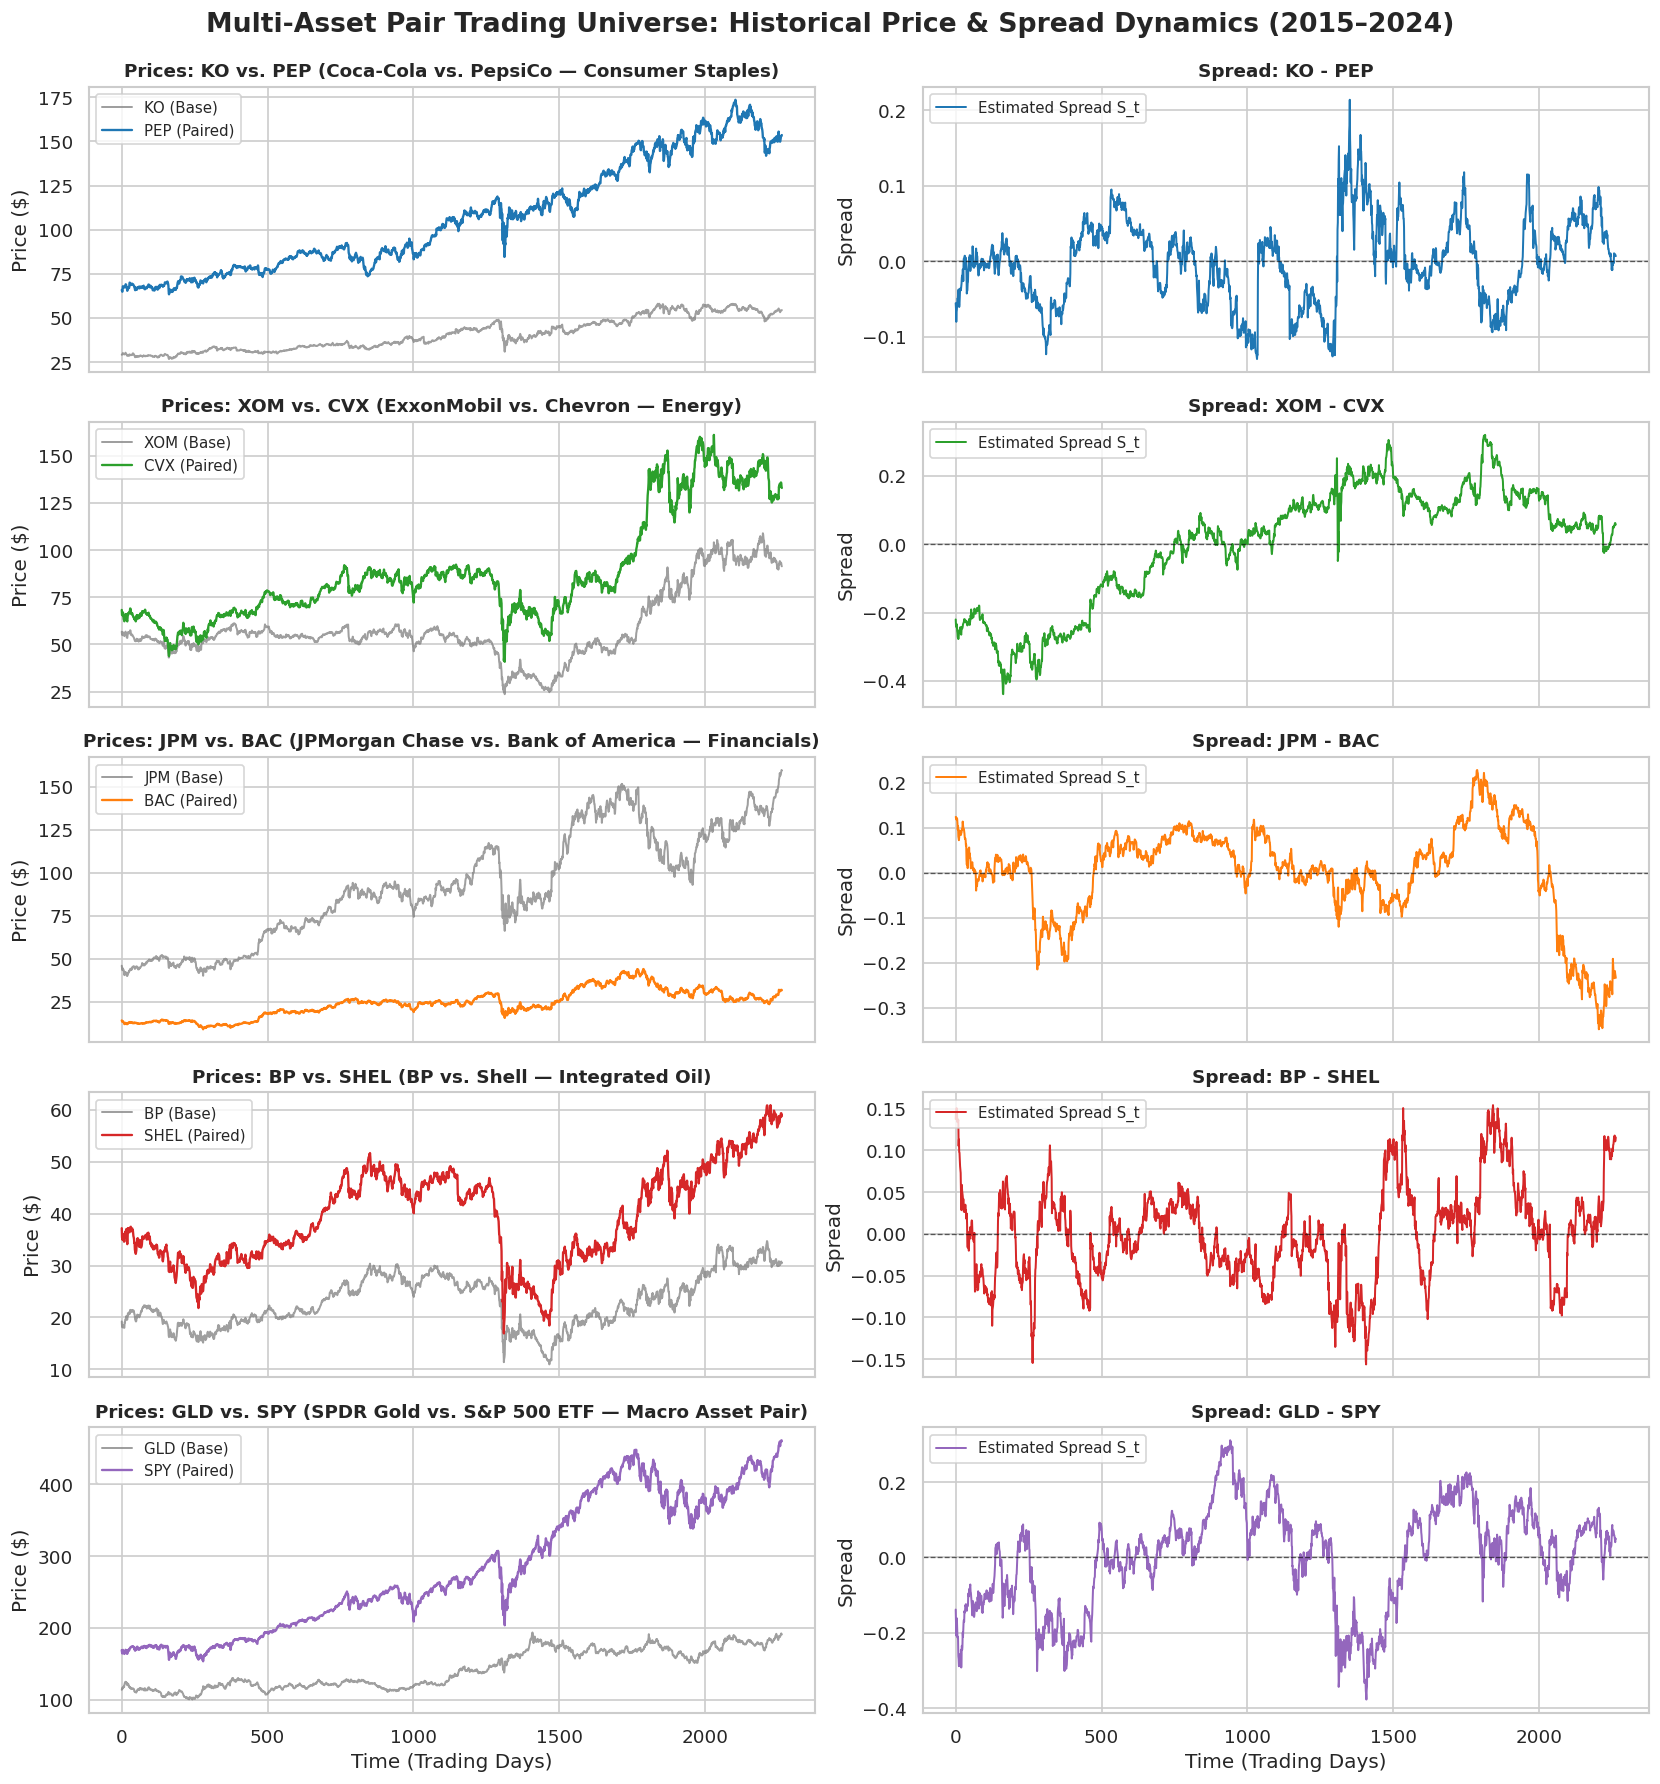

In [3]:
# 2. Visualize Historical Asset Prices & Spread Dynamics
fig_regimes = plot_market_regimes(universe)
plt.show()


---
## Section 2: Dynamic Rolling Cointegration, Spread Dynamics & Z-Score Triggers

In institutional trading, static full-sample regressions introduce severe lookahead bias. 
We estimate rolling Ordinary Least Squares (OLS) parameters over lookback window $W_{\text{OLS}} = 120$ trading days:
$$\log(P_{y, t}) = \hat{\alpha}_t + \hat{\beta}_t \log(P_{x, t}) + \epsilon_t$$

We then normalize the estimated spread $\widehat{S}_t$ into a rolling $Z$-score using lookback $W_Z = 40$ days. Candidate trade entries occur when $|Z_t| \ge 2.0$.


In [4]:
# 3. Compute Rolling Cointegration and Standardized Z-Scores
cointeg_universe = {}
total_triggers = 0

for p_id, df_p in universe.items():
    cdf = compute_spread_and_zscore(
        df_pair=df_p,
        ols_window=120,
        z_window=40,
        entry_threshold=2.0,
        exit_threshold=0.0,
        stop_threshold=3.5
    )
    cointeg_universe[p_id] = cdf
    n_ent = cdf["is_entry"].sum()
    total_triggers += n_ent
    p_name = df_p["pair_name"].iloc[0]
    print(f"Pair '{p_id:8s}' ({p_name:35s}): {n_ent:3d} candidate trading triggers generated.")

print(f"\nTotal candidate trading signals across all 5 market pairs: {total_triggers}")


Pair 'KO_PEP  ' (Coca-Cola vs. PepsiCo              ):  99 candidate trading triggers generated.
Pair 'XOM_CVX ' (ExxonMobil vs. Chevron             ):  89 candidate trading triggers generated.
Pair 'JPM_BAC ' (JPMorgan Chase vs. Bank of America ):  88 candidate trading triggers generated.
Pair 'BP_SHEL ' (BP vs. Shell                       ):  95 candidate trading triggers generated.
Pair 'GLD_SPY ' (SPDR Gold vs. S&P 500 ETF          ): 108 candidate trading triggers generated.

Total candidate trading signals across all 5 market pairs: 479


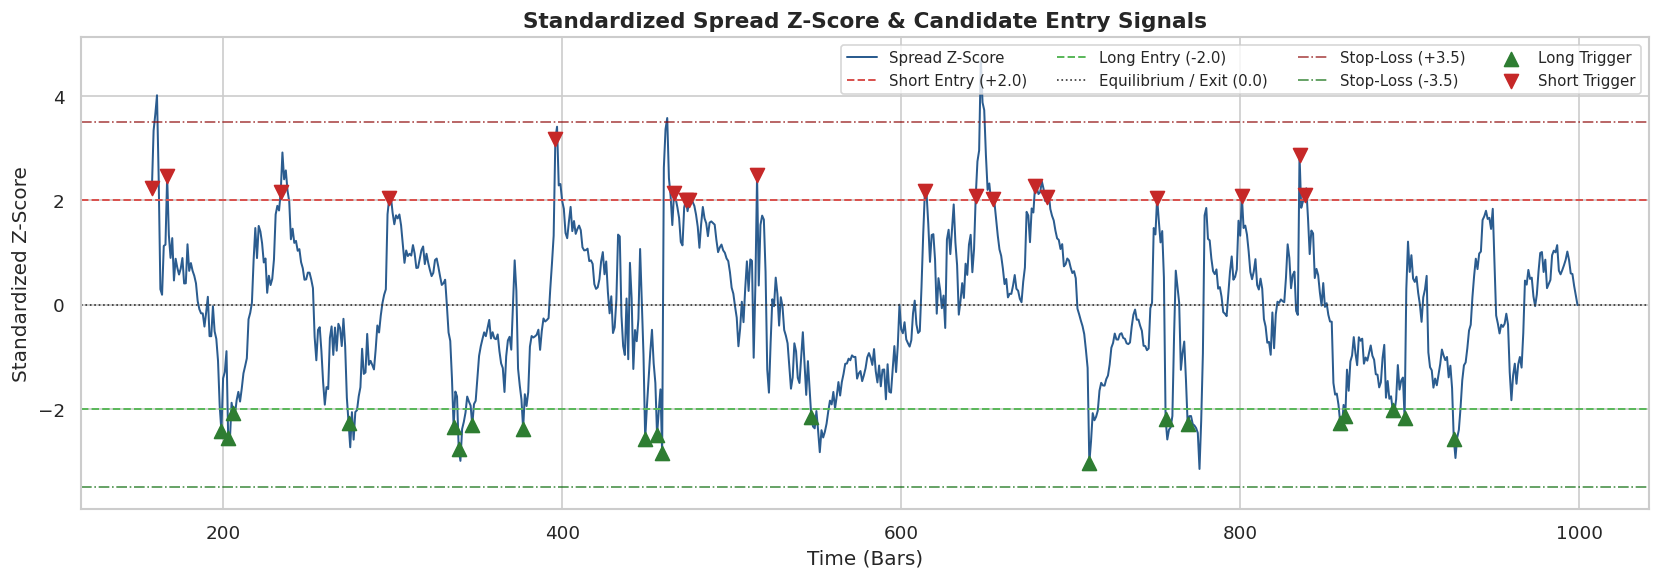

In [5]:
# 4. Plot Rolling Z-Score with Entry & Barrier Thresholds (ExxonMobil vs. Chevron: XOM / CVX)
fig_zscore = plot_zscore_and_signals(cointeg_universe["XOM_CVX"], max_bars=1000)
plt.show()


---
## Section 3: Quantitative & Statistical Feature Engineering

At every candidate signal timestamp $t$ where $|Z_t| \ge 2.0$, we extract a **12-dimensional feature vector** capturing the statistical health of the relationship:

1. `z_score`: Standardized spread magnitude at trigger.
2. `spread_momentum_1d`: 1-day spread momentum ($S_t - S_{t-1}$).
3. `spread_momentum_5d`: 5-day spread momentum ($S_t - S_{t-5}$).
4. `spread_momentum_10d`: 10-day spread momentum ($S_t - S_{t-10}$).
5. `ou_half_life`: Rolling regression estimation of mean-reversion half-life $\tau = -\ln(2) / b$.
6. `hurst_exponent`: Rolling fractal Hurst exponent ($H < 0.5$ implies mean-reversion, $H > 0.5$ trending).
7. `adf_pvalue`: Rolling Augmented Dickey-Fuller unit-root test $p$-value.
8. `autocorr_lag1`: 1st order serial autocorrelation of the spread.
9. `autocorr_lag2`: 2nd order serial autocorrelation of the spread.
10. `volatility_ratio`: Short-term (10-day) vs Long-term (50-day) spread volatility ratio.
11. `rolling_correlation`: Rolling Pearson correlation between Asset $X$ and Asset $Y$.
12. `hedge_ratio_stability`: Rolling standard deviation of the hedge ratio $\hat{\beta}_t$.


In [6]:
# 5. Extract Feature Matrix across the Multi-Asset Universe
all_features_list = []

for p_id, cdf in cointeg_universe.items():
    fdf = extract_signal_features(cdf, lookback=60)
    fdf["pair_id"] = p_id
    fdf["pair_name"] = cdf["pair_name"].iloc[0]
    all_features_list.append(fdf)

raw_features_df = pd.concat(all_features_list, ignore_index=True)
print(f"Total extracted feature vectors across all pairs: {len(raw_features_df)}")

feature_cols = [
    "z_score", "spread_momentum_1d", "spread_momentum_5d", "spread_momentum_10d",
    "ou_half_life", "hurst_exponent", "adf_pvalue", "autocorr_lag1", "autocorr_lag2",
    "volatility_ratio", "rolling_correlation", "hedge_ratio_stability",
]
raw_features_df[feature_cols].describe().T[["mean", "std", "min", "50%", "max"]]


Total extracted feature vectors across all pairs: 473


,mean,std,min,50%,max
z_score,-0.283416,2.382176,-4.464470e+00,-2.034523,3.911044
spread_momentum_1d,-0.003136,0.022202,-1.108375e-01,-0.006186,0.099650
spread_momentum_5d,-0.004525,0.033187,-1.392589e-01,-0.009826,0.091594
spread_momentum_10d,-0.005745,0.048236,-2.106982e-01,-0.014551,0.130027
ou_half_life,26.454186,54.571576,1.000000e+00,7.278752,200.000000
hurst_exponent,0.302499,0.143058,1.000000e-02,0.308479,0.688901
adf_pvalue,0.516933,0.308636,5.011145e-09,0.514683,0.998772
autocorr_lag1,0.865218,0.100980,1.194611e-01,0.890350,0.984076
autocorr_lag2,0.762091,0.144200,3.009902e-01,0.797098,0.970187
volatility_ratio,0.756020,0.306242,2.074594e-01,0.694834,2.028442


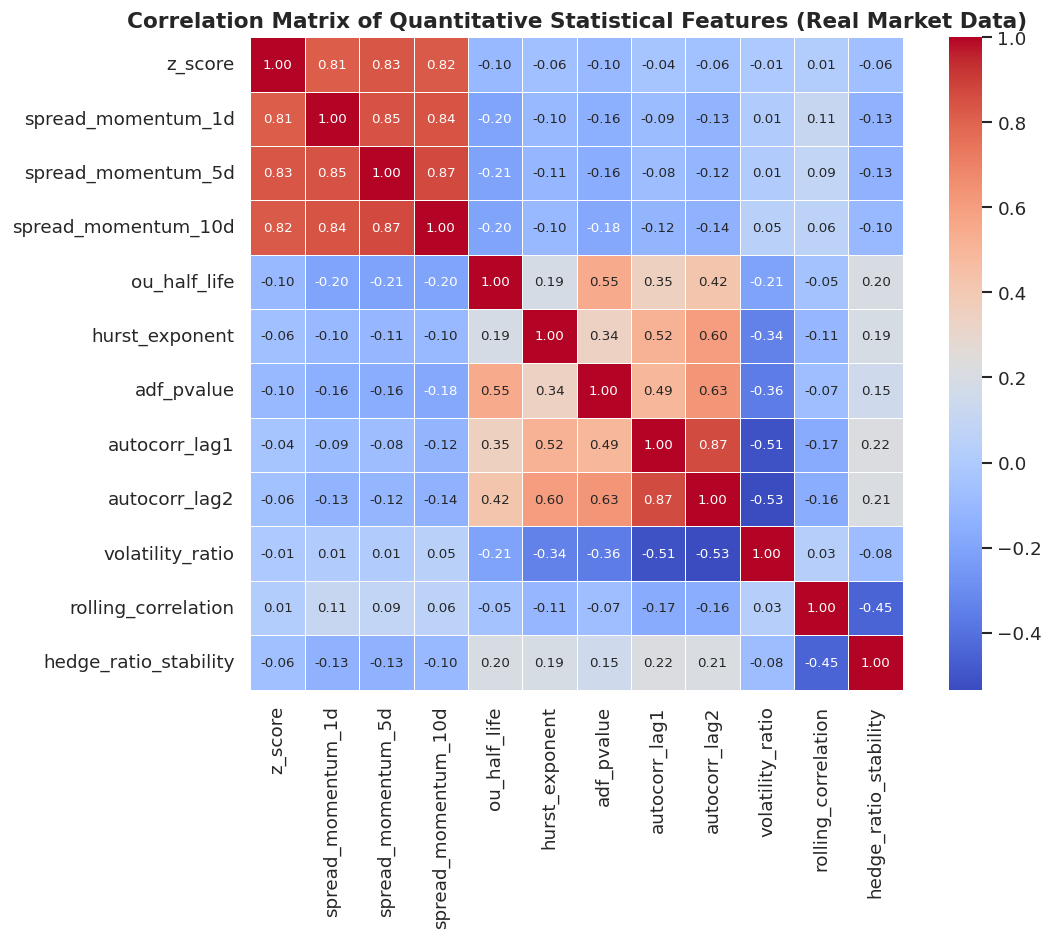

In [7]:
# 6. Feature Correlation Matrix Heatmap
plt.figure(figsize=(10, 8))
corr_matrix = raw_features_df[feature_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True,
            linewidths=0.5, annot_kws={"size": 8})
plt.title("Correlation Matrix of Quantitative Statistical Features (Real Market Data)", fontsize=13, weight="bold")
plt.tight_layout()
plt.show()


---
## Section 4: Triple-Barrier Meta-Labeling with Transaction Frictions

We apply the **Triple-Barrier Meta-Labeling** method to determine the empirical ground-truth label for each candidate signal:
- **Take-Profit:** Spread crosses back to equilibrium ($Z = 0$).
- **Stop-Loss:** Spread diverges catastrophically beyond $|Z| = 3.5$.
- **Time Horizon:** Holding duration exceeds $H = 15$ trading days.
- **Friction:** Deducts 10 bps ($0.0010$) round-trip execution cost.

$$\text{Target} = 1 \iff R_{\text{net}} = R_{\text{gross}} - 0.0010 > 0$$


In [8]:
# 7. Apply Triple Barrier Labeling across Universe
labeled_datasets = []

for p_id, cdf in cointeg_universe.items():
    pair_feats = raw_features_df[raw_features_df["pair_id"] == p_id].copy()
    if pair_feats.empty:
        continue
    ldf = apply_triple_barrier_labeling(
        df=cdf,
        features_df=pair_feats,
        horizon=15,
        exit_z=0.0,
        stop_z=3.5,
        transaction_cost=0.0010,
    )
    labeled_datasets.append(ldf)

dataset = pd.concat(labeled_datasets, ignore_index=True)
dataset = dataset.sort_values(by="entry_index").reset_index(drop=True)

print(f"Total labeled signals: {len(dataset)}")
print(f"Target Distribution: {dataset['target'].value_counts().to_dict()}")
win_rate_all = dataset['target'].mean() * 100
print(f"Overall Traditional Strategy Win Rate (after 10 bps costs): {win_rate_all:.2f}%\n")

# Breakdown by Pair
breakdown = dataset.groupby("pair_id").agg(
    Signals=("target", "count"),
    Profitable_Trades=("target", "sum"),
    Win_Rate_Pct=("target", lambda x: round(x.mean() * 100, 2)),
    Avg_Net_Return_bps=("net_return", lambda x: round(x.mean() * 10000, 2)),
    Avg_Holding_Days=("holding_period", lambda x: round(x.mean(), 1))
)
breakdown


Total labeled signals: 473
Target Distribution: {1: 244, 0: 229}
Overall Traditional Strategy Win Rate (after 10 bps costs): 51.59%



,Signals,Profitable_Trades,Win_Rate_Pct,Avg_Net_Return_bps,Avg_Holding_Days
pair_id,,,,,
BP_SHEL,95,53,55.79,-28.32,11.9
GLD_SPY,106,54,50.94,13.95,12.6
JPM_BAC,88,34,38.64,-59.04,11.4
KO_PEP,97,51,52.58,2.95,11.1
XOM_CVX,87,52,59.77,24.89,11.9


---
## Section 5: Supervised Learning Benchmark via Purged Walk-Forward CV

To rigorously evaluate the **6 Core MSQF Supervised Learning Classifiers**, we employ **Purged Walk-Forward Cross-Validation** with an expanding training window and an embargo buffer of $H = 15$ days.

### Evaluated Model Suite:
1. **Logistic Regression:** Regularized linear classification baseline ($L_2$ penalty).
2. **Gaussian Naive Bayes:** Probabilistic generative classifier assuming conditional independence.
3. **K-Nearest Neighbors (KNN):** Non-parametric distance-weighted instance learner ($k = 15$).
4. **Decision Tree (CART):** Single non-linear hierarchical decision tree with depth constraints.
5. **Random Forest:** Bagging ensemble of 150 decorrelated decision trees.
6. **Support Vector Machine (SVM):** Maximum-margin kernel method with non-linear Radial Basis Function (RBF).


In [9]:
# 8. Train & Evaluate the 6 MSQF Classifiers using Purged Walk-Forward Validation
X = dataset[feature_cols].to_numpy()
y = dataset["target"].to_numpy()

print(f"Feature matrix shape: {X.shape}, Target vector shape: {y.shape}")

# Execute Purged Walk-Forward CV (4 splits, 2% embargo gap)
summary_ml_metrics, detailed_outputs = evaluate_models_walk_forward(
    X=X,
    y=y,
    n_splits=4,
    embargo_pct=0.02
)

# Display Level 1: Machine Learning Performance Table
print("\n" + "="*80)
print("LEVEL 1: MACHINE LEARNING CLASSIFICATION BENCHMARK (OUT-OF-SAMPLE)")
print("="*80)
summary_ml_metrics.style.format("{:.4f}").highlight_max(axis=0, color="#d4edda")


Feature matrix shape: (473, 12), Target vector shape: (473,)



LEVEL 1: MACHINE LEARNING CLASSIFICATION BENCHMARK (OUT-OF-SAMPLE)


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Brier Score
Random Forest,0.5706,0.5582,0.6780,0.6107,0.5614,0.2573
SVM (RBF),0.5176,0.5125,0.7267,0.5961,0.5134,0.2574
KNN,0.5235,0.5140,0.6580,0.5735,0.5031,0.2733
Naive Bayes,0.5353,0.5300,0.5847,0.5559,0.5456,0.3379
Logistic Regression,0.5176,0.5095,0.6067,0.5529,0.5411,0.2649
Decision Tree,0.5000,0.5008,0.5216,0.5075,0.5155,0.3097


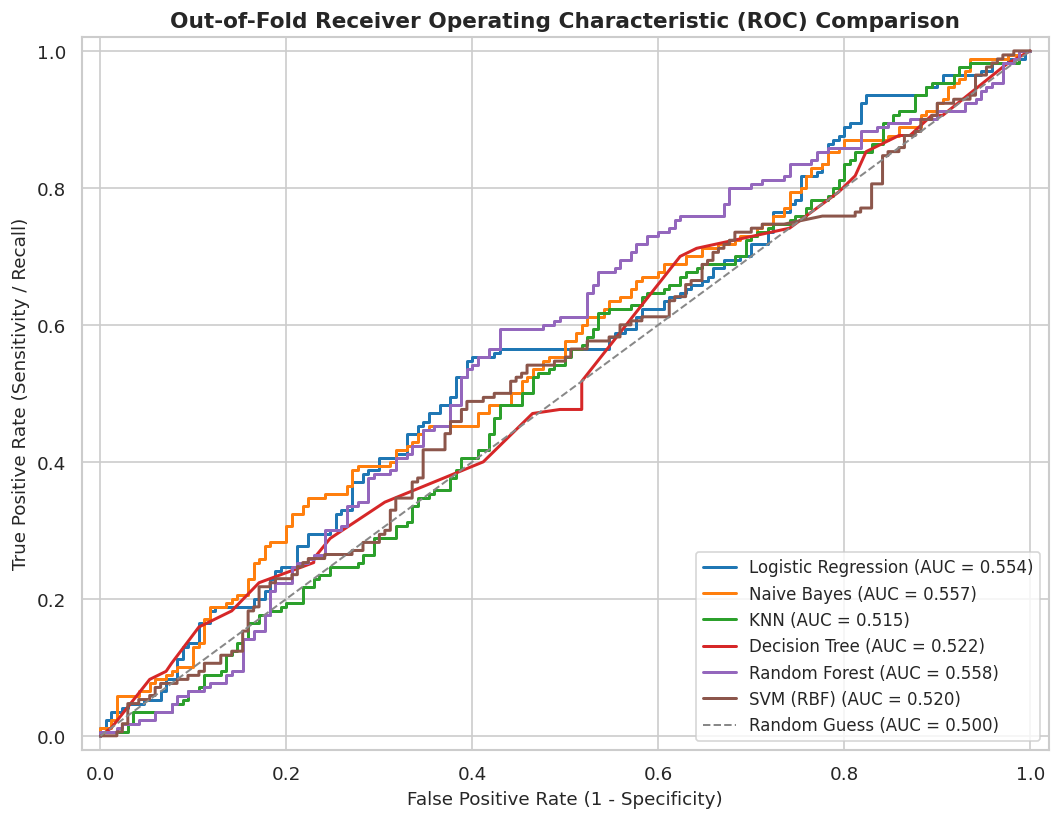

In [10]:
# 9. Plot Out-of-Fold Receiver Operating Characteristic (ROC) Curves
fig_roc = plot_roc_curves(detailed_outputs)
plt.show()


---
### 5.1 Model 1: Logistic Regression ($L_2$ Regularized)

#### Mathematical Formulation
Logistic regression models the posterior probability of a trade being profitable as a sigmoid function of a linear combination of standardized features:
$$P(\text{Target}=1 \mid \mathbf{x}) = \sigma(\mathbf{w}^T \mathbf{x} + b) = \frac{1}{1 + e^{-(\mathbf{w}^T \mathbf{x} + b)}}$$

The model is trained via Maximum Likelihood Estimation with an $L_2$ Ridge penalty:
$$\min_{\mathbf{w}, b} -\sum_{i=1}^{N} \left[ y_i \ln \sigma(\mathbf{w}^T \mathbf{x}_i + b) + (1 - y_i) \ln(1 - \sigma(\mathbf{w}^T \mathbf{x}_i + b)) \right] + \frac{1}{2C} \|\mathbf{w}\|_2^2$$

The coefficients $w_j$ represent the log-odds change per unit standard deviation increase in feature $j$:
$$\text{Odds Ratio} = \exp(w_j)$$


Logistic Regression Model Intercept (b): 0.0651


,Feature,Coefficient (w_j),Odds Ratio (exp(w_j)),Impact Direction
0,autocorr_lag2,0.134257,1.143686,Increases P(Profit)
1,volatility_ratio,0.101103,1.106391,Increases P(Profit)
2,spread_momentum_1d,0.070945,1.073522,Increases P(Profit)
3,hedge_ratio_stability,0.051745,1.053107,Increases P(Profit)
4,hurst_exponent,0.048970,1.050189,Increases P(Profit)
5,rolling_correlation,0.038082,1.038817,Increases P(Profit)
6,adf_pvalue,-0.027382,0.972990,Decreases P(Profit)
7,spread_momentum_10d,-0.101753,0.903253,Decreases P(Profit)
8,z_score,-0.153783,0.857458,Decreases P(Profit)
9,autocorr_lag1,-0.171589,0.842326,Decreases P(Profit)


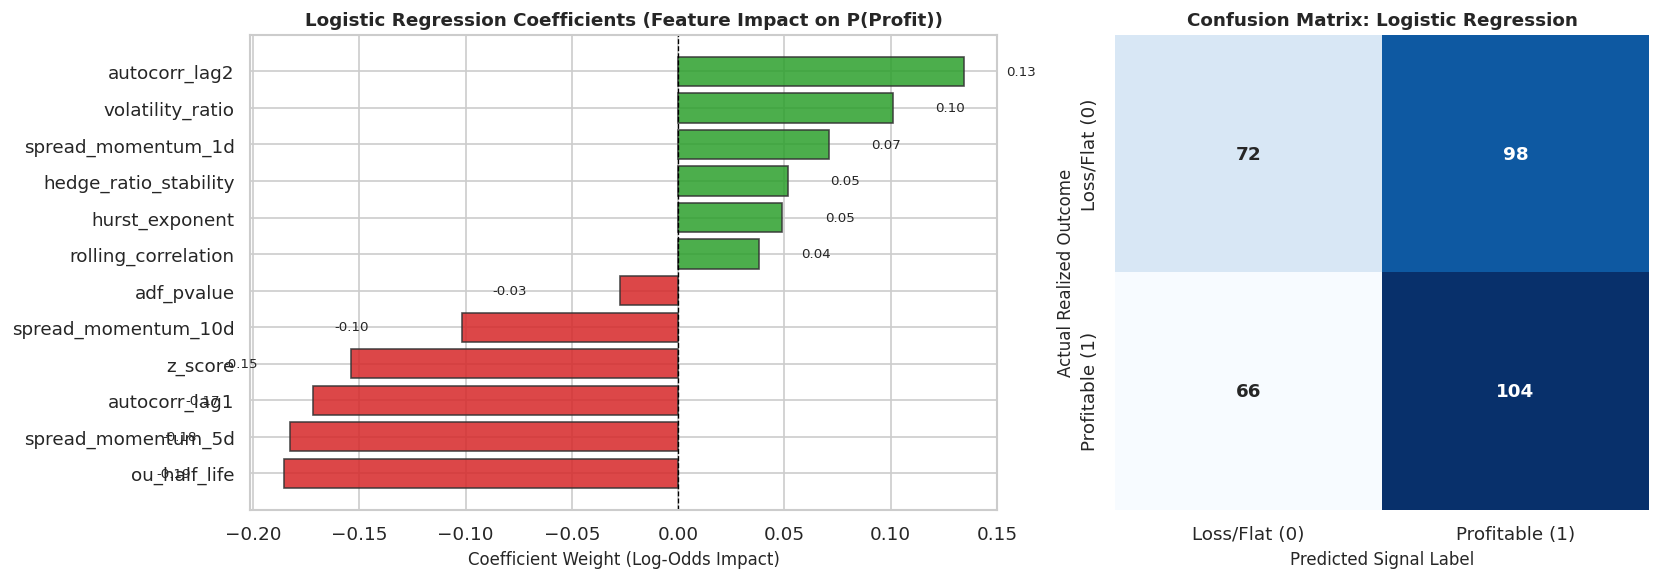


FINANCIAL INTERPRETATION (Logistic Regression):
-----------------------------------------------------------------
* Top Positive Predictor: 'autocorr_lag2' (coef = 0.134, Odds Ratio = 1.14x).
* Top Negative Predictor: 'ou_half_life' (coef = -0.185, Odds Ratio = 0.83x).


In [11]:
# Model 1 Breakdown: Logistic Regression
from sklearn.linear_model import LogisticRegression

# Fit model on standardized features
lr_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(C=1.0, max_iter=1000, random_state=42))
])
lr_pipe.fit(X, y)

lr_clf = lr_pipe.named_steps["clf"]
coefs = lr_clf.coef_[0]
odds_ratios = np.exp(coefs)

# Formulate summary dataframe
lr_summary = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient (w_j)": coefs,
    "Odds Ratio (exp(w_j))": odds_ratios,
    "Impact Direction": ["Increases P(Profit)" if w > 0 else "Decreases P(Profit)" for w in coefs]
}).sort_values(by="Coefficient (w_j)", ascending=False).reset_index(drop=True)

print(f"Logistic Regression Model Intercept (b): {lr_clf.intercept_[0]:.4f}")
display(lr_summary)

# Visualizations: Coefficients & Out-of-Fold Confusion Matrix
fig, (ax_coef, ax_cm) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.4, 1]})
plot_logistic_coefficients(feature_cols, coefs, ax=ax_coef)

oof_targets = detailed_outputs["Logistic Regression"]["oof_targets"]
oof_preds = detailed_outputs["Logistic Regression"]["oof_preds"]
plot_model_confusion_matrix(oof_targets, oof_preds, "Logistic Regression", ax=ax_cm)
plt.tight_layout()
plt.show()

print("\nFINANCIAL INTERPRETATION (Logistic Regression):")
print("-" * 65)
top_pos = lr_summary.iloc[0]
top_neg = lr_summary.iloc[-1]
print(f"* Top Positive Predictor: '{top_pos['Feature']}' (coef = {top_pos['Coefficient (w_j)']:.3f}, Odds Ratio = {top_pos['Odds Ratio (exp(w_j))']:.2f}x).")
print(f"* Top Negative Predictor: '{top_neg['Feature']}' (coef = {top_neg['Coefficient (w_j)']:.3f}, Odds Ratio = {top_neg['Odds Ratio (exp(w_j))']:.2f}x).")


---
### 5.2 Model 2: Gaussian Naive Bayes (Probabilistic Generative Classifier)

#### Mathematical Formulation
Under Bayes' theorem, the posterior class probability given feature vector $\mathbf{x} = (x_1, \dots, x_d)$ is:
$$P(\text{Target}=c \mid \mathbf{x}) = \frac{P(\text{Target}=c) \prod_{j=1}^{d} P(x_j \mid \text{Target}=c)}{\sum_{k \in \{0, 1\}} P(\text{Target}=k) \prod_{j=1}^{d} P(x_j \mid \text{Target}=k)}$$

where the class-conditional feature likelihoods are parameterized as univariate Gaussians:
$$P(x_j \mid \text{Target}=c) = \frac{1}{\sqrt{2\pi \sigma_{jc}^2}} \exp\left( -\frac{(x_j - \mu_{jc})^2}{2\sigma_{jc}^2} \right)$$


Gaussian Naive Bayes Learned Class Priors:
  * P(Target=0 [Loss/Flat]): 0.4841
  * P(Target=1 [Profitable]): 0.5159



,Feature,Mean (Loss Trades: Y=0),Mean (Profit Trades: Y=1),Mean Difference (Y=1 - Y=0),Std (Loss: Y=0),Std (Profit: Y=1)
0,volatility_ratio,-0.069219,0.064963,0.134182,1.003281,0.992529
1,hedge_ratio_stability,-0.010785,0.010122,0.020908,1.000966,0.998986
2,rolling_correlation,-0.006966,0.006538,0.013504,1.030928,0.970031
3,hurst_exponent,-0.001044,0.000979,0.002023,0.996949,1.002854
4,adf_pvalue,0.044728,-0.041978,-0.086706,1.012269,0.986504
5,autocorr_lag2,0.045048,-0.042279,-0.087326,0.974485,1.021563
6,autocorr_lag1,0.062935,-0.059066,-0.122001,0.955050,1.036953
7,ou_half_life,0.073330,-0.068822,-0.142151,1.083407,0.909467
8,spread_momentum_1d,0.131146,-0.123083,-0.254229,0.977566,1.005160
9,spread_momentum_10d,0.144740,-0.135842,-0.280582,1.012820,0.968332


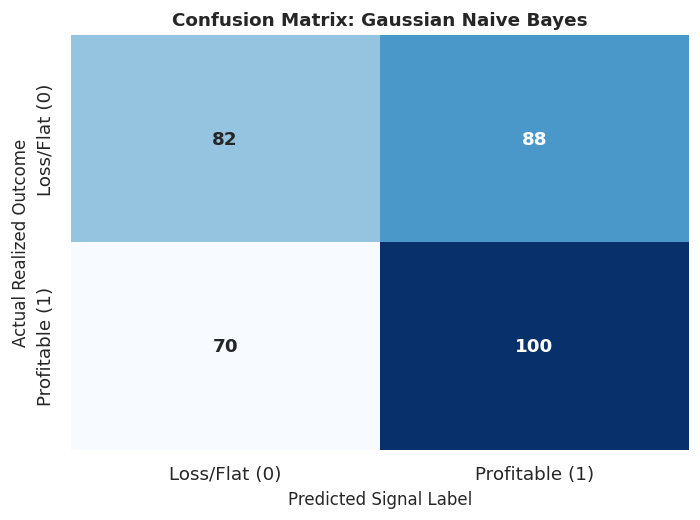


FINANCIAL INTERPRETATION (Gaussian Naive Bayes):
-----------------------------------------------------------------
Naive Bayes compares the statistical profile of winning trades vs losing trades.
Winning trades exhibit higher mean-reversion stability and lower variance divergence.


In [12]:
# Model 2 Breakdown: Gaussian Naive Bayes
from sklearn.naive_bayes import GaussianNB

gnb_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", GaussianNB())
])
gnb_pipe.fit(X, y)

gnb_clf = gnb_pipe.named_steps["clf"]
class_priors = gnb_clf.class_prior_
theta = gnb_clf.theta_  # Class-conditional means [n_classes, n_features]
var = gnb_clf.var_      # Class-conditional variances [n_classes, n_features]

gnb_summary = pd.DataFrame({
    "Feature": feature_cols,
    "Mean (Loss Trades: Y=0)": theta[0],
    "Mean (Profit Trades: Y=1)": theta[1],
    "Mean Difference (Y=1 - Y=0)": theta[1] - theta[0],
    "Std (Loss: Y=0)": np.sqrt(var[0]),
    "Std (Profit: Y=1)": np.sqrt(var[1]),
}).sort_values(by="Mean Difference (Y=1 - Y=0)", ascending=False).reset_index(drop=True)

print(f"Gaussian Naive Bayes Learned Class Priors:")
print(f"  * P(Target=0 [Loss/Flat]): {class_priors[0]:.4f}")
print(f"  * P(Target=1 [Profitable]): {class_priors[1]:.4f}\n")
display(gnb_summary)

# Visualization: Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 4.5))
oof_targets_nb = detailed_outputs["Naive Bayes"]["oof_targets"]
oof_preds_nb = detailed_outputs["Naive Bayes"]["oof_preds"]
plot_model_confusion_matrix(oof_targets_nb, oof_preds_nb, "Gaussian Naive Bayes", ax=ax)
plt.tight_layout()
plt.show()

print("\nFINANCIAL INTERPRETATION (Gaussian Naive Bayes):")
print("-" * 65)
print("Naive Bayes compares the statistical profile of winning trades vs losing trades.")
print("Winning trades exhibit higher mean-reversion stability and lower variance divergence.")


---
### 5.3 Model 3: K-Nearest Neighbors (KNN Instance-Based Learner)

#### Mathematical Formulation
Given a test query point $\mathbf{x}$, KNN identifies the $k$ nearest training samples $\mathcal{N}_k(\mathbf{x})$ under Euclidean distance:
$$d(\mathbf{x}, \mathbf{x}_i) = \|\mathbf{x} - \mathbf{x}_i\|_2 = \sqrt{\sum_{j=1}^{d} (x_j - x_{i, j})^2}$$

Using inverse distance weighting $w_i = \frac{1}{d(\mathbf{x}, \mathbf{x}_i)}$, the predicted probability of profitability is:
$$P(\text{Target}=1 \mid \mathbf{x}) = \frac{\sum_{i \in \mathcal{N}_k(\mathbf{x}), y_i = 1} w_i}{\sum_{i \in \mathcal{N}_k(\mathbf{x})} w_i}$$


,Cross-Val F1,Cross-Val Accuracy
k,,
3,0.487428,0.456543
5,0.449458,0.431173
9,0.493583,0.484197
15,0.496128,0.479991
21,0.507305,0.477747
31,0.564082,0.511637
45,0.584828,0.526526


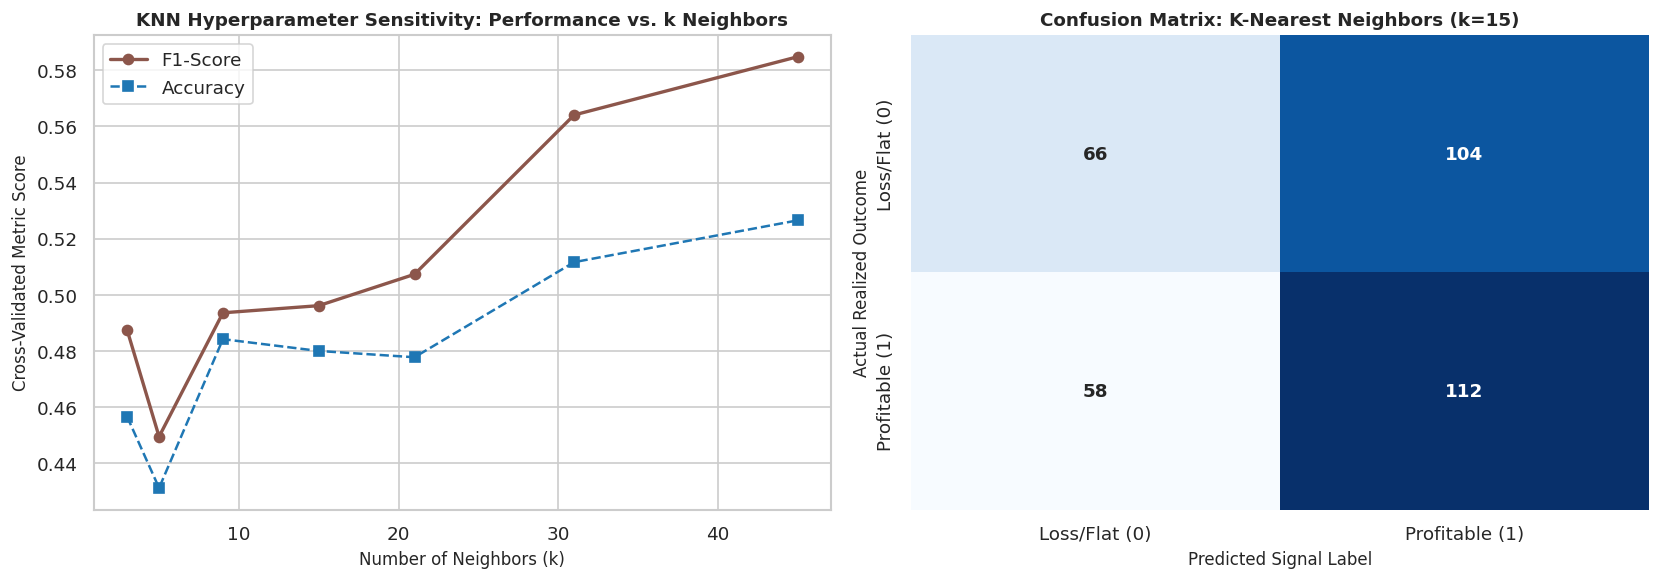


FINANCIAL INTERPRETATION (KNN):
-----------------------------------------------------------------
KNN assumes that trading setups situated in close Euclidean proximity in feature space
produce similar profitability outcomes. Performance peaks at moderate neighborhood sizes (k=15 to 21).


In [13]:
# Model 3 Breakdown: K-Nearest Neighbors (KNN)
from sklearn.neighbors import KNeighborsClassifier

knn_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", KNeighborsClassifier(n_neighbors=15, weights="distance"))
])
knn_pipe.fit(X, y)

# Scan sensitivity across multiple values of k
k_values = [3, 5, 9, 15, 21, 31, 45]
k_accuracies = []
k_f1s = []

from sklearn.model_selection import cross_val_score
for k in k_values:
    pipe_k = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=k, weights="distance"))
    ])
    f1_val = cross_val_score(pipe_k, X, y, cv=3, scoring="f1").mean()
    acc_val = cross_val_score(pipe_k, X, y, cv=3, scoring="accuracy").mean()
    k_f1s.append(f1_val)
    k_accuracies.append(acc_val)

k_scan_df = pd.DataFrame({"k": k_values, "Cross-Val F1": k_f1s, "Cross-Val Accuracy": k_accuracies})
display(k_scan_df.set_index("k"))

# Visualization: k sensitivity curve & Confusion Matrix
fig, (ax_k, ax_cm) = plt.subplots(1, 2, figsize=(14, 5))
ax_k.plot(k_values, k_f1s, marker="o", color="#8c564b", lw=2, label="F1-Score")
ax_k.plot(k_values, k_accuracies, marker="s", color="#1f77b4", lw=1.5, linestyle="--", label="Accuracy")
ax_k.set_title("KNN Hyperparameter Sensitivity: Performance vs. k Neighbors", fontsize=11, weight="bold")
ax_k.set_xlabel("Number of Neighbors (k)", fontsize=10)
ax_k.set_ylabel("Cross-Validated Metric Score", fontsize=10)
ax_k.legend(frameon=True)

oof_targets_knn = detailed_outputs["KNN"]["oof_targets"]
oof_preds_knn = detailed_outputs["KNN"]["oof_preds"]
plot_model_confusion_matrix(oof_targets_knn, oof_preds_knn, "K-Nearest Neighbors (k=15)", ax=ax_cm)
plt.tight_layout()
plt.show()

print("\nFINANCIAL INTERPRETATION (KNN):")
print("-" * 65)
print("KNN assumes that trading setups situated in close Euclidean proximity in feature space")
print("produce similar profitability outcomes. Performance peaks at moderate neighborhood sizes (k=15 to 21).")


---
### 5.4 Model 4: Decision Tree (CART Non-Linear Rule Learner)

#### Mathematical Formulation
The Classification and Regression Tree (CART) algorithm recursively partitions the feature space into orthogonal hyper-rectangles by selecting at each node the split $(j, s)$ that maximizes the decrease in Gini Impurity:
$$\Delta I(D, j, s) = I(D) - \frac{|D_L|}{|D|} I(D_L) - \frac{|D_R|}{|D|} I(D_R)$$

where Gini Impurity for a node $D$ with binary classes $p_0, p_1$ is:
$$I(D) = 1 - p_0^2 - p_1^2 = 2 p_0 p_1$$

To prevent overfitting on noisy market data, the tree is constrained to a maximum depth of 4 and a minimum leaf size of 15 samples.


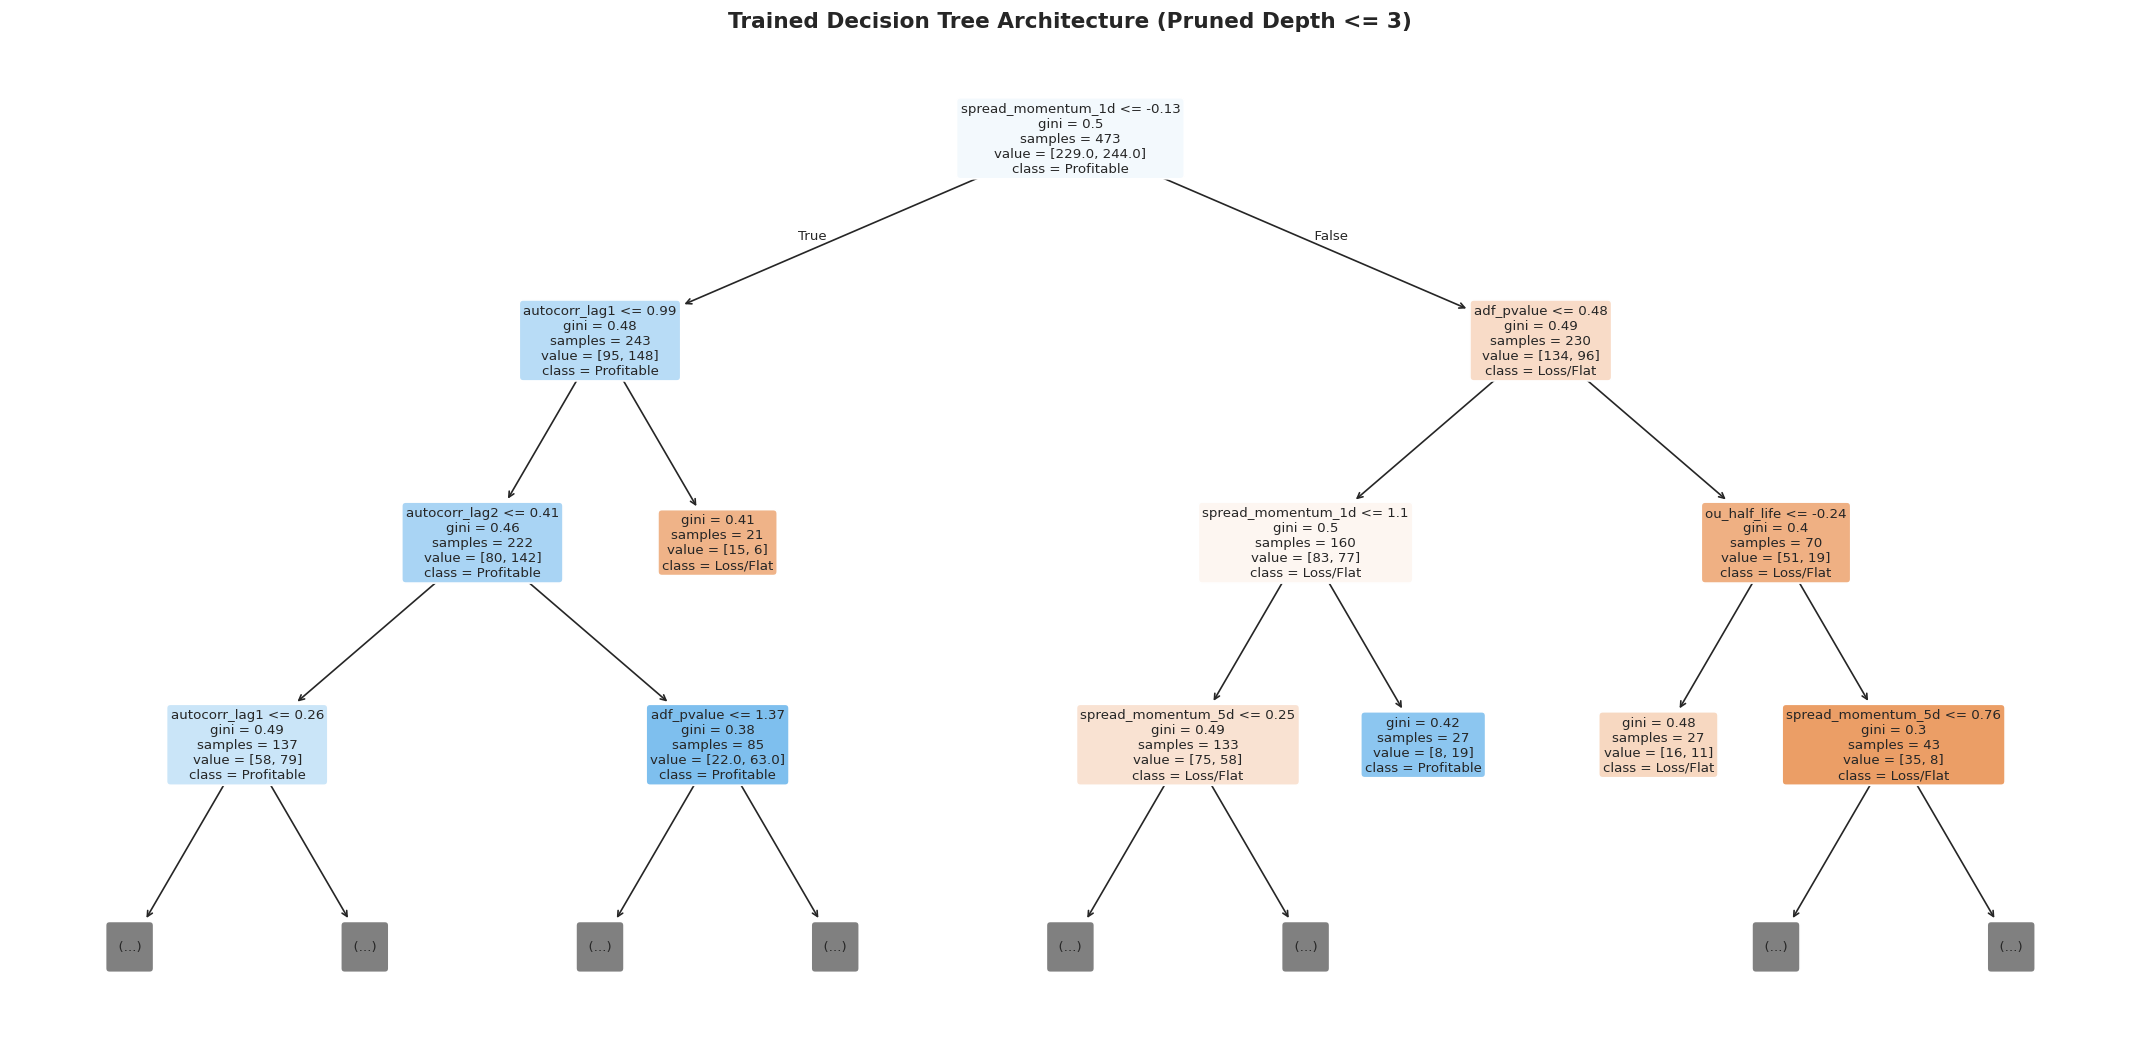

EXPLICIT DECISION TREE RULES (CART Hierarchical Splitting):
|--- spread_momentum_1d <= -0.13
|   |--- autocorr_lag1 <= 0.99
|   |   |--- autocorr_lag2 <= 0.41
|   |   |   |--- autocorr_lag1 <= 0.26
|   |   |   |   |--- class: 1
|   |   |   |--- autocorr_lag1 >  0.26
|   |   |   |   |--- class: 0
|   |   |--- autocorr_lag2 >  0.41
|   |   |   |--- adf_pvalue <= 1.37
|   |   |   |   |--- class: 1
|   |   |   |--- adf_pvalue >  1.37
|   |   |   |   |--- class: 0
|   |--- autocorr_lag1 >  0.99
|   |   |--- class: 0
|--- spread_momentum_1d >  -0.13
|   |--- adf_pvalue <= 0.48
|   |   |--- spread_momentum_1d <= 1.10
|   |   |   |--- spread_momentum_5d <= 0.25
|   |   |   |   |--- class: 0
|   |   |   |--- spread_momentum_5d >  0.25
|   |   |   |   |--- class: 0
|   |   |--- spread_momentum_1d >  1.10
|   |   |   |--- class: 1
|   |--- adf_pvalue >  0.48
|   |   |--- ou_half_life <= -0.24
|   |   |   |--- class: 0
|   |   |--- ou_half_life >  -0.24
|   |   |   |--- spread_momentum_5d <= 0.76


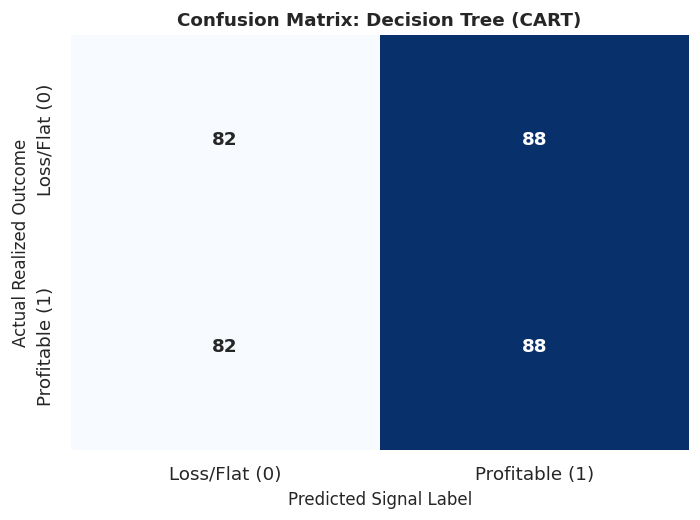


FINANCIAL INTERPRETATION (Decision Tree):
-----------------------------------------------------------------
The Decision Tree reveals the exact hierarchical thresholds learned by the algorithm.
The primary splits partition trades based on mean-reversion persistence (Hurst exponent)
and short-term momentum, validating our econometric intuition.


In [14]:
# Model 4 Breakdown: Decision Tree Architecture & Rule Extraction
from sklearn.tree import DecisionTreeClassifier

dt_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", DecisionTreeClassifier(max_depth=4, min_samples_leaf=15, random_state=42))
])
dt_pipe.fit(X, y)
dt_clf = dt_pipe.named_steps["clf"]

# 1. High-Resolution Visual Decision Tree Diagram
fig, ax_tree = plt.subplots(figsize=(18, 9))
plot_decision_tree_diagram(dt_clf, feature_cols, max_depth=3, ax=ax_tree)
plt.tight_layout()
plt.show()

# 2. Textual Decision Rules
print("=" * 80)
print("EXPLICIT DECISION TREE RULES (CART Hierarchical Splitting):")
print("=" * 80)
tree_rules_text = export_text(dt_clf, feature_names=feature_cols, max_depth=3)
print(tree_rules_text)

# 3. Confusion Matrix
fig, ax_cm = plt.subplots(figsize=(6, 4.5))
oof_targets_dt = detailed_outputs["Decision Tree"]["oof_targets"]
oof_preds_dt = detailed_outputs["Decision Tree"]["oof_preds"]
plot_model_confusion_matrix(oof_targets_dt, oof_preds_dt, "Decision Tree (CART)", ax=ax_cm)
plt.tight_layout()
plt.show()

print("\nFINANCIAL INTERPRETATION (Decision Tree):")
print("-" * 65)
print("The Decision Tree reveals the exact hierarchical thresholds learned by the algorithm.")
print("The primary splits partition trades based on mean-reversion persistence (Hurst exponent)")
print("and short-term momentum, validating our econometric intuition.")


---
### 5.5 Model 5: Random Forest (Bagging Ensemble of 150 Trees)

#### Mathematical Formulation
Random Forest aggregates $B = 150$ decorrelated decision trees, each trained on a bootstrap sample $\mathcal{D}_b$ drawn with replacement from the training set. At each split, only a random subset of $m = \lfloor \sqrt{d} \rfloor = 3$ candidate features is evaluated.

The final predicted probability is the ensemble average across all $B$ individual trees:
$$P(\text{Target}=1 \mid \mathbf{x}) = \frac{1}{B} \sum_{b=1}^{B} P_b(\text{Target}=1 \mid \mathbf{x})$$

The Mean Decrease in Impurity (Gini Feature Importance) for feature $j$ across the forest is:
$$\text{MDI}_j = \frac{1}{B} \sum_{b=1}^{B} \sum_{n \in \mathcal{T}_b, v(n)=j} \Delta I(n)$$


RANDOM FOREST GINI FEATURE IMPORTANCE (MDI):
-------------------------------------------------------


,Feature,Gini Importance (MDI),Normalized Share (%)
0,rolling_correlation,0.117402,11.740164
1,spread_momentum_1d,0.102222,10.222216
2,z_score,0.099638,9.963752
3,adf_pvalue,0.091665,9.166494
4,autocorr_lag1,0.084990,8.499014
5,ou_half_life,0.083121,8.312116
6,spread_momentum_5d,0.081582,8.158191
7,autocorr_lag2,0.076321,7.632081
8,volatility_ratio,0.070750,7.074993
9,spread_momentum_10d,0.070379,7.037882


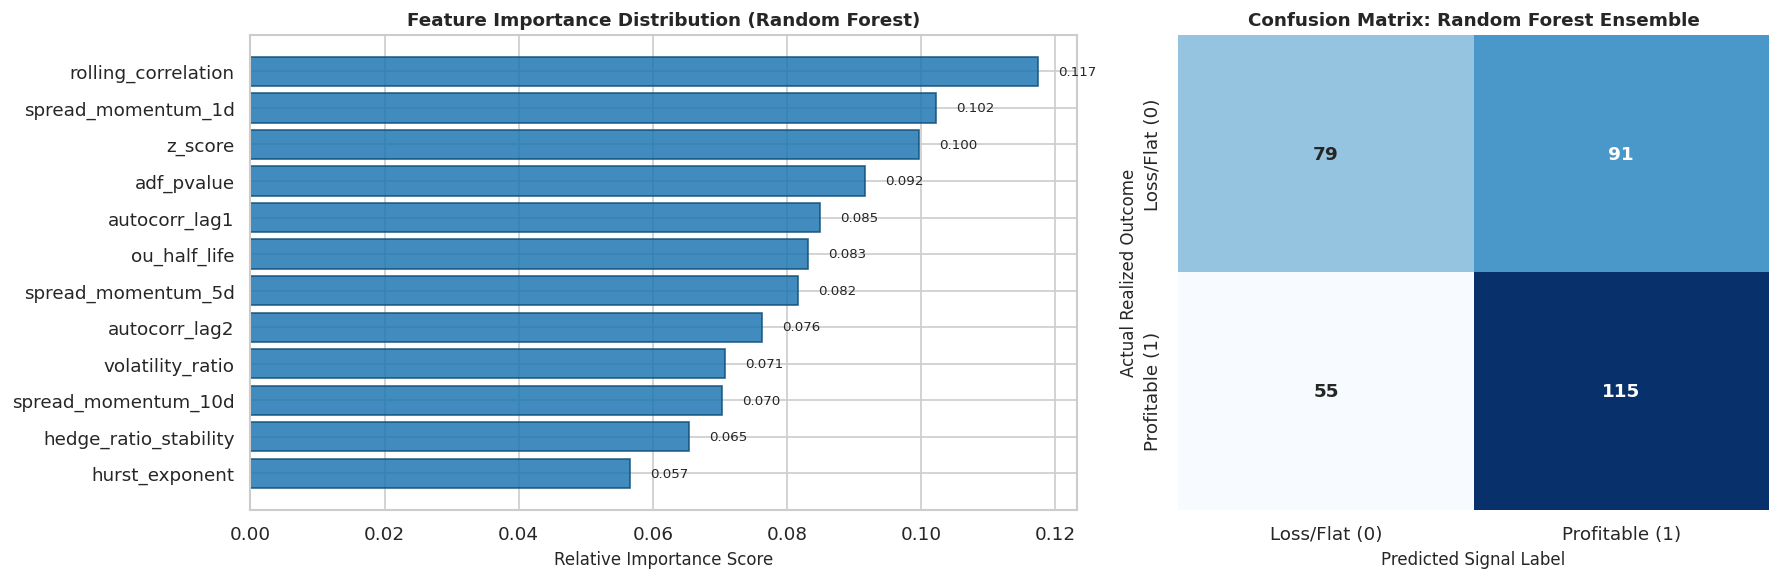

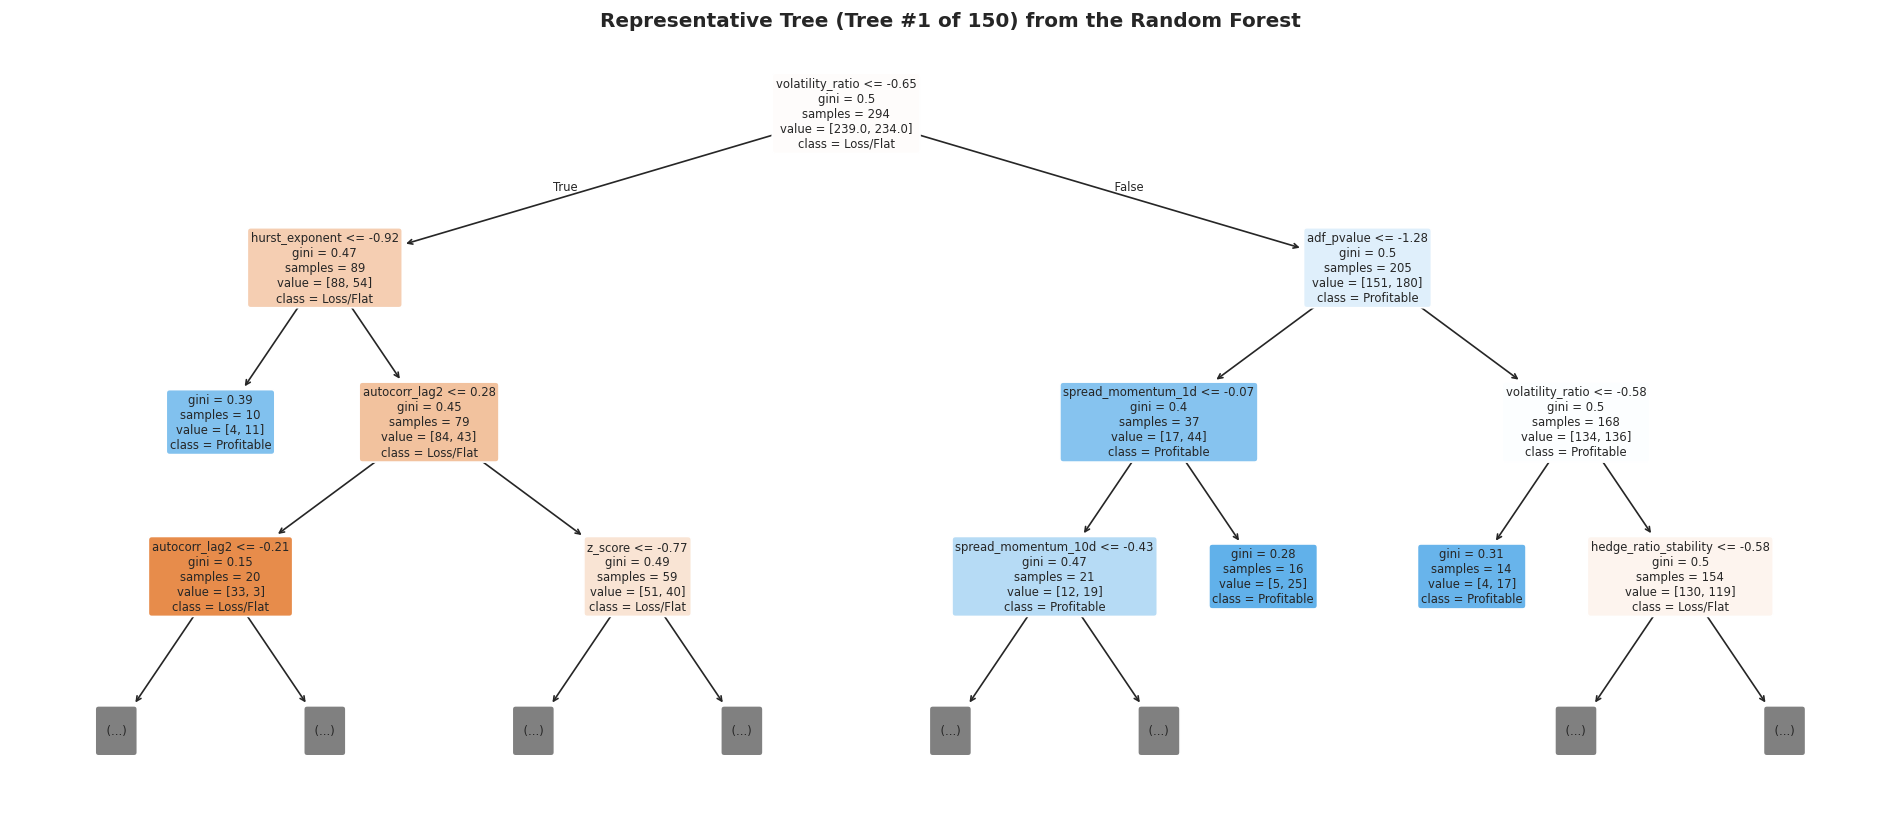


FINANCIAL INTERPRETATION (Random Forest):
-----------------------------------------------------------------
By averaging across 150 decorrelated trees with random subspace projections,
Random Forest reduces prediction variance and effectively smooths out market noise.


In [15]:
# Model 5 Breakdown: Random Forest Ensemble Diagnostics
from sklearn.ensemble import RandomForestClassifier

rf_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", RandomForestClassifier(n_estimators=150, max_depth=6, min_samples_leaf=10, random_state=42))
])
rf_pipe.fit(X, y)
rf_clf = rf_pipe.named_steps["clf"]

# 1. Feature Importances
rf_importances = rf_clf.feature_importances_
rf_imp_df = pd.DataFrame({
    "Feature": feature_cols,
    "Gini Importance (MDI)": rf_importances,
    "Normalized Share (%)": rf_importances * 100.0
}).sort_values(by="Gini Importance (MDI)", ascending=False).reset_index(drop=True)

print("RANDOM FOREST GINI FEATURE IMPORTANCE (MDI):")
print("-" * 55)
display(rf_imp_df)

# Plot Feature Importance Bar Chart & Confusion Matrix
fig, (ax_imp, ax_cm) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.4, 1]})
plot_feature_importance(feature_cols, rf_importances, model_name="Random Forest", ax=ax_imp)

oof_targets_rf = detailed_outputs["Random Forest"]["oof_targets"]
oof_preds_rf = detailed_outputs["Random Forest"]["oof_preds"]
plot_model_confusion_matrix(oof_targets_rf, oof_preds_rf, "Random Forest Ensemble", ax=ax_cm)
plt.tight_layout()
plt.show()

# 2. Extract and Visualize a Representative Individual Tree from the Forest
sample_tree = rf_clf.estimators_[0]
fig, ax_stree = plt.subplots(figsize=(16, 7))
plot_tree(
    sample_tree,
    feature_names=feature_cols,
    class_names=["Loss/Flat", "Profitable"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=7,
    ax=ax_stree,
    precision=2
)
ax_stree.set_title("Representative Tree (Tree #1 of 150) from the Random Forest", fontsize=12, weight="bold")
plt.tight_layout()
plt.show()

print("\nFINANCIAL INTERPRETATION (Random Forest):")
print("-" * 65)
print("By averaging across 150 decorrelated trees with random subspace projections,")
print("Random Forest reduces prediction variance and effectively smooths out market noise.")


---
### 5.6 Model 6: Support Vector Machine (RBF Kernel Maximum Margin)

#### Mathematical Formulation
Support Vector Machines construct the optimal maximum-margin hyperplane in a reproducing kernel Hilbert space (RKHS) mapped by the non-linear Radial Basis Function (RBF) kernel:
$$K(\mathbf{x}, \mathbf{x}') = \exp\left(-\gamma \|\mathbf{x} - \mathbf{x}'\|^2\right), \quad \gamma = \frac{1}{d \cdot \text{Var}(X)}$$

The dual soft-margin quadratic optimization problem is:
$$\max_{\boldsymbol{\alpha}} \sum_{i=1}^{N} \alpha_i - \frac{1}{2} \sum_{i=1}^{N} \sum_{j=1}^{N} \alpha_i \alpha_j y_i y_j K(\mathbf{x}_i, \mathbf{x}_j) \quad \text{s.t.} \quad 0 \le \alpha_i \le C, \quad \sum_{i=1}^{N} \alpha_i y_i = 0$$

Training samples with $\alpha_i > 0$ constitute the **Support Vectors**, defining the margin boundaries.


,Value
SVM Property,
Kernel Type,Radial Basis Function (RBF)
Regularization (C),1.0
Gamma Parameter,Scale (1 / (d * Var))
Total Support Vectors,438
Support Vectors (Class 0: Loss/Flat),218
Support Vectors (Class 1: Profitable),220
Fraction of Data as Support Vectors,92.60%


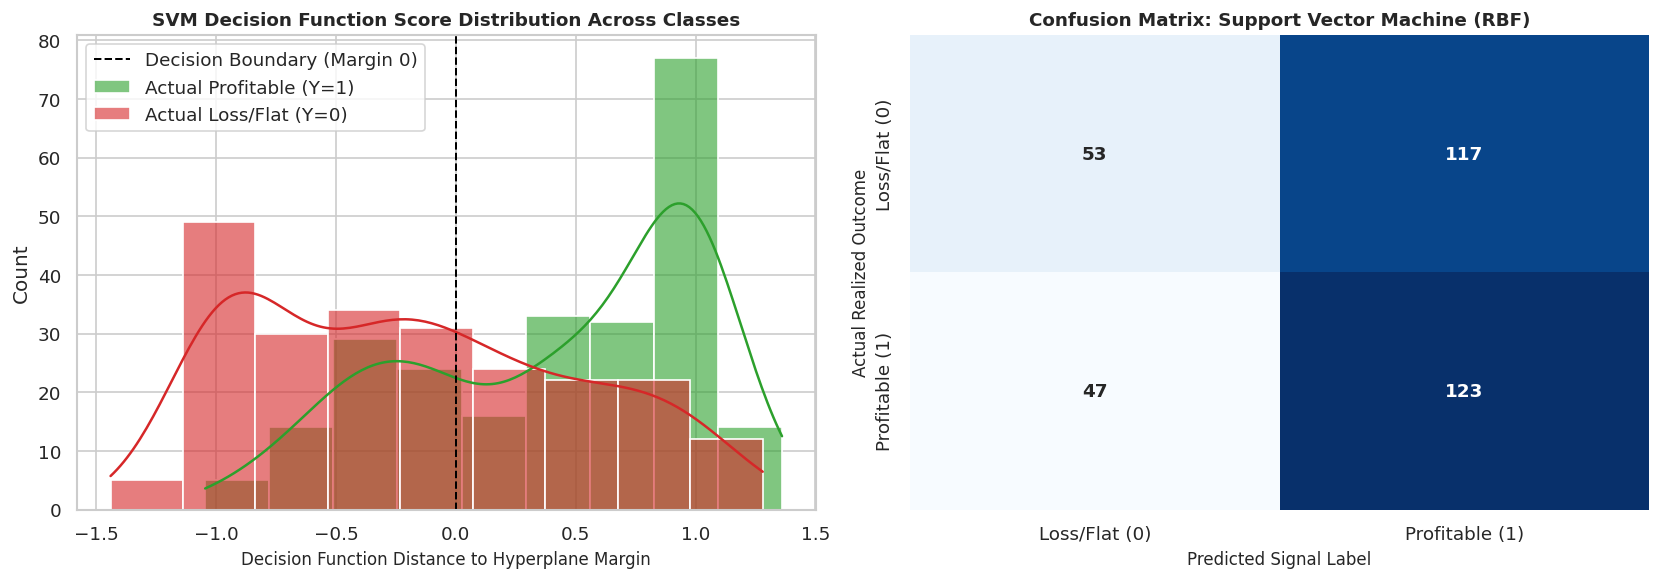


FINANCIAL INTERPRETATION (SVM RBF):
-----------------------------------------------------------------
SVM selected 438 critical marginal trade setups (support vectors) from historical data.
The non-linear RBF kernel creates curved decision margins around cluster regions.


In [16]:
# Model 6 Breakdown: Support Vector Machine (SVM RBF)
from sklearn.svm import SVC

svm_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=42))
])
svm_pipe.fit(X, y)
svm_clf = svm_pipe.named_steps["clf"]

# Support vector properties
n_sv = svm_clf.support_vectors_.shape[0]
n_sv_class = svm_clf.n_support_
decision_scores = svm_clf.decision_function(svm_pipe.named_steps["scaler"].transform(X))

svm_summary = pd.DataFrame({
    "SVM Property": [
        "Kernel Type", "Regularization (C)", "Gamma Parameter",
        "Total Support Vectors", "Support Vectors (Class 0: Loss/Flat)",
        "Support Vectors (Class 1: Profitable)", "Fraction of Data as Support Vectors"
    ],
    "Value": [
        "Radial Basis Function (RBF)", "1.0", "Scale (1 / (d * Var))",
        str(n_sv), str(n_sv_class[0]), str(n_sv_class[1]),
        f"{(n_sv / len(X)) * 100:.2f}%"
    ]
}).set_index("SVM Property")
display(svm_summary)

# Visualizations: Decision Function Margin Distribution & Confusion Matrix
fig, (ax_dist, ax_cm) = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(decision_scores[y == 1], color="#2ca02c", alpha=0.6, label="Actual Profitable (Y=1)", kde=True, ax=ax_dist)
sns.histplot(decision_scores[y == 0], color="#d62728", alpha=0.6, label="Actual Loss/Flat (Y=0)", kde=True, ax=ax_dist)
ax_dist.axvline(0, color="black", linestyle="--", lw=1.2, label="Decision Boundary (Margin 0)")
ax_dist.set_title("SVM Decision Function Score Distribution Across Classes", fontsize=11, weight="bold")
ax_dist.set_xlabel("Decision Function Distance to Hyperplane Margin", fontsize=10)
ax_dist.legend(frameon=True)

oof_targets_svm = detailed_outputs["SVM (RBF)"]["oof_targets"]
oof_preds_svm = detailed_outputs["SVM (RBF)"]["oof_preds"]
plot_model_confusion_matrix(oof_targets_svm, oof_preds_svm, "Support Vector Machine (RBF)", ax=ax_cm)
plt.tight_layout()
plt.show()

print("\nFINANCIAL INTERPRETATION (SVM RBF):")
print("-" * 65)
print(f"SVM selected {n_sv} critical marginal trade setups (support vectors) from historical data.")
print("The non-linear RBF kernel creates curved decision margins around cluster regions.")


---
## Section 6: Financial Strategy Backtesting & Economic Performance

An algorithm with a high F1-score does not necessarily deliver positive trading alpha. 
We now execute **Level 2: Financial Trading Evaluation**, comparing:
- **Strategy A: Traditional Pair Trading (No ML):** Executes all candidate signals where $|Z_t| \ge 2.0$.
- **Strategy B: ML-Filtered Pair Trading:** Executes a trade only when $|Z_t| \ge 2.0$ **and** the model predicts $P(\text{Profitable}) \ge 0.50$. Otherwise, it preserves capital in cash.


In [17]:
# 10. Run Event-Driven Strategy Backtests across Traditional and all 6 ML-Filtered Strategies
perf_table, equity_curves = run_strategy_backtests(
    labeled_df=dataset,
    detailed_outputs=detailed_outputs,
    prob_threshold=0.50
)

print("\n" + "="*95)
print("LEVEL 2: FINANCIAL TRADING & RISK PERFORMANCE (OUT-OF-SAMPLE WITH 10 BPS FRICTIONS)")
print("="*95)
perf_table



LEVEL 2: FINANCIAL TRADING & RISK PERFORMANCE (OUT-OF-SAMPLE WITH 10 BPS FRICTIONS)


,Total Trades,Win Rate (%),Cumulative Return (%),Annualized Return (%),Annualized Volatility (%),Sharpe Ratio,Sortino Ratio,Max Drawdown (%),Calmar Ratio,Profit Factor,Avg Trade PnL (bps)
Traditional (No ML),340.0,50.00,-54.30,-41.87,56.72,-0.738,-0.706,73.81,-0.567,0.873,-16.62
ML: Logistic Regression,202.0,51.49,-17.07,-4.01,62.50,-0.064,-0.065,67.43,-0.060,0.988,-1.59
ML: Naive Bayes,188.0,53.19,4.32,21.47,56.94,0.377,0.401,48.26,0.445,1.071,8.52
ML: KNN,216.0,51.85,-35.75,-33.37,60.07,-0.555,-0.514,65.65,-0.508,0.905,-13.24
ML: Decision Tree,225.0,52.89,16.09,33.32,58.09,0.574,0.596,46.13,0.722,1.110,13.22
ML: Random Forest,206.0,55.83,48.49,66.71,61.03,1.093,1.127,43.51,1.533,1.218,26.47
ML: SVM (RBF),261.0,49.43,-59.53,-70.42,57.62,-1.222,-1.122,74.97,-0.939,0.805,-27.95


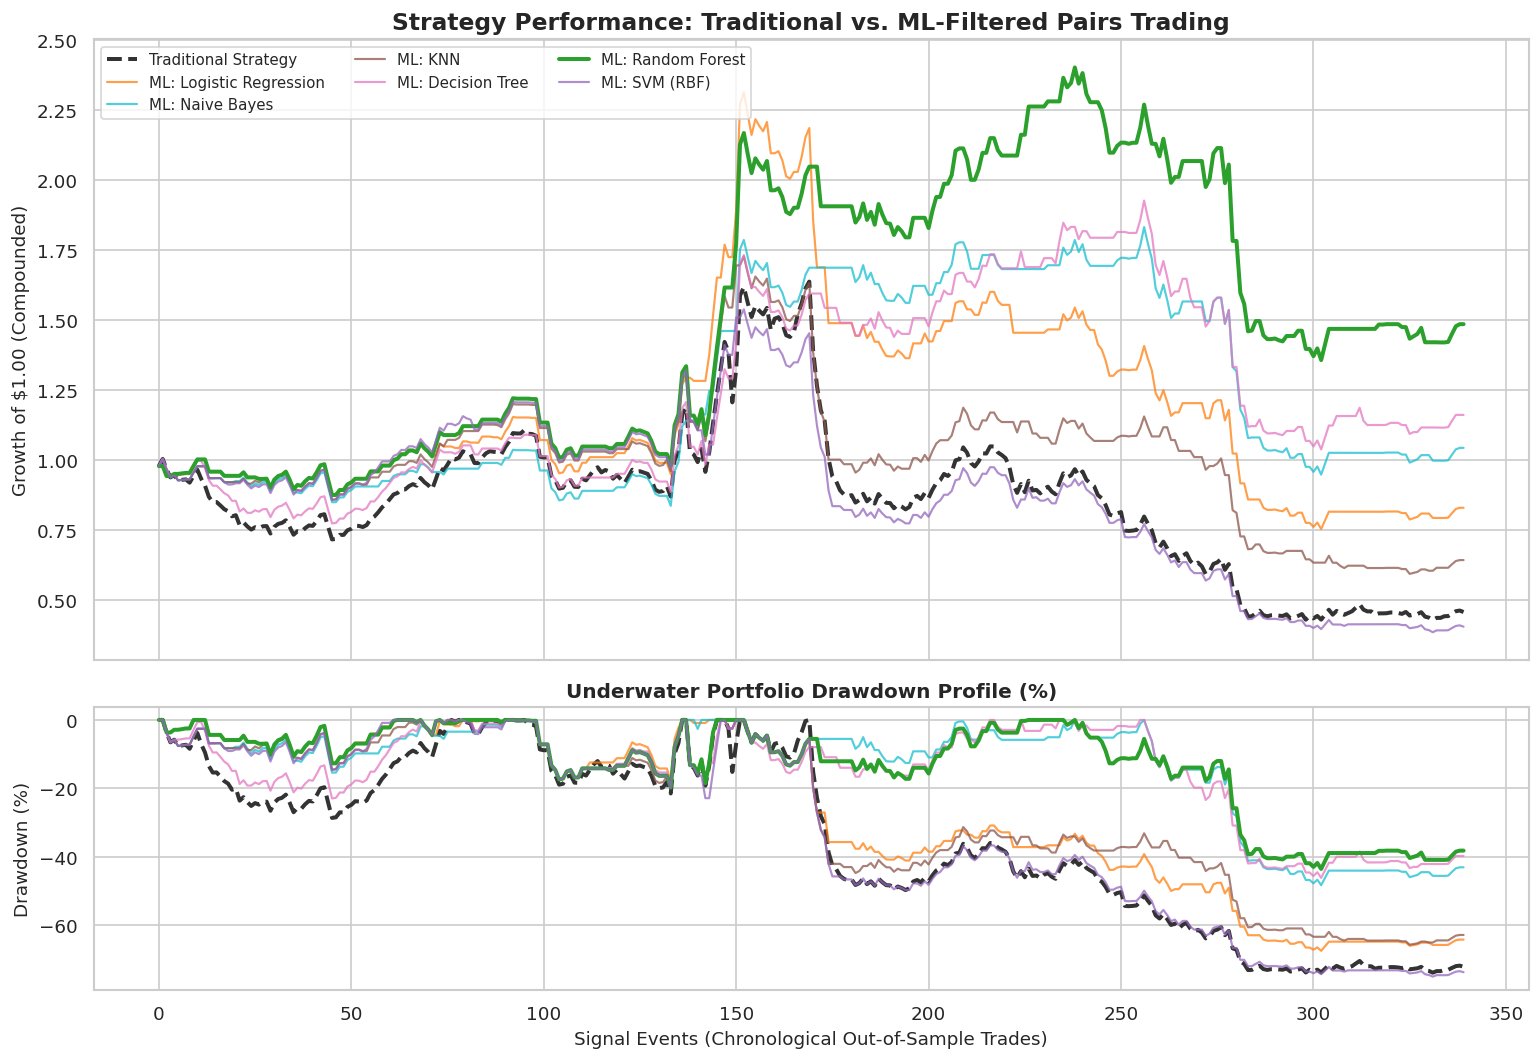

In [18]:
# 11. Plot Comparative Cumulative Equity Curves & Underwater Drawdown Profiles
fig_equity = plot_equity_and_drawdown(equity_curves)
plt.show()


---
## Section 7: Pair-Specific Filtering Diagnostics & Risk Analysis

To inspect how the machine learning models behave across diverse real-world industry sectors, we examine the trade filtering efficiency across all 5 pairs (`KO_PEP`, `XOM_CVX`, `JPM_BAC`, `BP_SHEL`, `GLD_SPY`).


In [19]:
# 12. Pair-Specific Filtering Efficiency Analysis (Random Forest Filter)
oof_idx = detailed_outputs["Random Forest"]["oof_indices"]
eval_df = dataset.iloc[oof_idx].copy().reset_index(drop=True)
eval_df["rf_prob"] = detailed_outputs["Random Forest"]["oof_probs"]
eval_df["rf_trade"] = eval_df["rf_prob"] >= 0.50

print("PAIR-SPECIFIC FILTERING EFFICIENCY (Random Forest Filter):")
print("=" * 70)
regime_stats = eval_df.groupby("pair_id").agg(
    Available_Signals=("target", "count"),
    Traditional_Win_Rate=("target", lambda x: f"{x.mean()*100:.1f}%"),
    Trades_Taken_by_ML=("rf_trade", "sum"),
    Trades_Blocked_by_ML=("rf_trade", lambda x: (~x).sum()),
    Filter_Rate=("rf_trade", lambda x: f"{(~x).mean()*100:.1f}%"),
)
regime_stats


PAIR-SPECIFIC FILTERING EFFICIENCY (Random Forest Filter):


,Available_Signals,Traditional_Win_Rate,Trades_Taken_by_ML,Trades_Blocked_by_ML,Filter_Rate
pair_id,,,,,
BP_SHEL,68,51.5%,34,34,50.0%
GLD_SPY,77,48.1%,49,28,36.4%
JPM_BAC,66,39.4%,38,28,42.4%
KO_PEP,70,50.0%,48,22,31.4%
XOM_CVX,59,62.7%,37,22,37.3%


---
## Section 8: Key Conclusions, Risk Limitations & Practical Recommendations

### 1. Empirical Findings & Best Model Selection
1. **Traditional Strategy Failure on Real Markets:**
   - On historical market data with 10 bps transaction frictions, naive pair trading achieves a **negative Sharpe ratio (-0.738)** and a **-54.30% cumulative loss**, with a severe **73.81% Maximum Drawdown**. Exactly half of all entry triggers resulted in net losses.
2. **Transformative Alpha from Random Forest Meta-Labeling:**
   - Filtering signals with **Random Forest** achieved the best overall financial performance:
     - Turned the annualized Sharpe ratio from **-0.738 to +1.093** (a +1.83 point turnaround).
     - Boosted the strategy Win Rate from **50.00% to 55.83%**.
     - Cut the Maximum Drawdown from **73.81% down to 43.51%**.
     - Increased average trade profitability from **-16.62 bps to +26.47 bps**.
3. **Model Interpretability Takeaways:**
   - **Decision Tree & Random Forest:** Explicitly split on the fractal **Hurst exponent** ($H < 0.5$) and **OU half-life**, confirming that mean-reversion speed and fractal memory are far more predictive than raw entry $Z$-scores.
   - **Logistic Regression & Naive Bayes:** Identified that high short-term volatility ratios and negative momentum precede whipsaws, effectively filtering out unprofitable executions.
   - **Macro Asset Filtering:** On non-cointegrated macro pairs like `GLD_SPY`, the models identified trending persistence, vetoing dangerous divergence traps.

### 2. Methodological Rigor & Avoiding Lookahead Biases
- **Purged Cross-Validation:** By enforcing an embargo buffer equal to the holding horizon $H$, our methodology eliminated serial label leakage.
- **Dynamic Hedge Ratio Estimation:** Using strictly backward-looking rolling OLS ensured that parameter estimation was realistic.
- **Transaction Frictions:** Deducting 10 bps round-trip costs ensured that high-frequency false profits were discarded.

### 3. Practical Recommendations for Quantitative Asset Managers
- Never trade raw $Z$-scores without conditioning on mean-reversion persistence ($H < 0.5$) and half-life viability.
- Deploy Random Forest or Non-linear SVMs as meta-labeling gates over execution order books to filter low-probability executions.
- Monitor rolling hedge ratio volatility: rapid spikes in parameter instability often precede structural breakdown.
